# Zomato Restaurant Analysis — Final Notebook
**Purpose:** Clean the Zomato dataset, answer the project business questions, visualize results, and export a dashboard-ready CSV for Power BI.

**Run order:** Use **Kernel → Restart Kernel and Run All** after placing `zomato.csv` in the same folder as this notebook or in one of the dataset folders checked below.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 1. Load the dataset

In [2]:
# Look for the original CSV in common locations, including beside this notebook.
candidate_paths = [
    Path.cwd() / "zomato.csv",
    Path.cwd() / "Dataset" / "zomato.csv",
    Path.cwd() / "dataset" / "zomato.csv",
    Path.cwd() / "Downloads" / "zomato.csv",
    Path.home() / "Downloads" / "zomato.csv",
    Path.home() / "Downloads" / "archive" / "zomato.csv",
    Path.home() / "Desktop" / "Zomato Restaurant Analysis" / "Dataset" / "zomato.csv",
    Path.home() / "Desktop" / "Namaste Restaurant Analysis" / "Dataset" / "zomato.csv",
]
dataset_path = next((p for p in candidate_paths if p.exists()), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find zomato.csv. Put it beside this notebook, or update candidate_paths "
        "to the actual location of your dataset."
    )

df = pd.read_csv(dataset_path, low_memory=False)
df.columns = df.columns.astype(str).str.strip()
print(f"Dataset loaded: {dataset_path}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: C:\Users\acer\Downloads\archive\zomato.csv
Shape: 51,717 rows × 17 columns


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


## 2. Inspect data quality

In [3]:
print("Columns:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
display(df.info())
print("\nDuplicate rows:", int(df.duplicated().sum()))
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_percent", ascending=False)
display(missing_summary)

Columns:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_ty

None


Duplicate rows: 0


,missing_count,missing_percent
dish_liked,28078,54.29
rate,7775,15.03
phone,1208,2.34
approx_cost(for two people),346,0.67
rest_type,227,0.44
cuisines,45,0.09
location,21,0.04


## 3. Clean ratings, costs, and categorical fields

In [4]:
df_clean = df.copy()

# Normalize rating values such as '4.1/5'; invalid values become NaN.
if "rate" in df_clean.columns:
    rating_text = (
        df_clean["rate"].astype("string").str.strip()
        .str.replace("/5", "", regex=False)
        .replace(["NEW", "-", "", "nan", "None", "<NA>"], pd.NA)
    )
    df_clean["rate_numeric"] = pd.to_numeric(rating_text, errors="coerce")
    df_clean.loc[~df_clean["rate_numeric"].between(0, 5), "rate_numeric"] = np.nan
else:
    df_clean["rate_numeric"] = np.nan
    print("Warning: 'rate' column not found; rate_numeric will be empty.")

cost_col = "approx_cost(for two people)"
if cost_col in df_clean.columns:
    cost_text = (
        df_clean[cost_col].astype("string").str.strip()
        .str.replace(",", "", regex=False)
        .replace(["", "nan", "None", "<NA>"], pd.NA)
    )
    df_clean["cost_numeric"] = pd.to_numeric(cost_text, errors="coerce")
else:
    df_clean["cost_numeric"] = np.nan
    print(f"Warning: '{cost_col}' column not found; cost_numeric will be empty.")

for col in ["location", "rest_type", "cuisines", "online_order", "book_table"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype("string").str.strip()
        df_clean[col] = df_clean[col].replace(["", "nan", "None", "<NA>"], pd.NA)

print("Cleaning complete.")
print("Rows:", len(df_clean))
print("Valid ratings:", int(df_clean["rate_numeric"].notna().sum()))
print("Missing/invalid ratings:", int(df_clean["rate_numeric"].isna().sum()))
print("Valid cost values:", int(df_clean["cost_numeric"].notna().sum()))
print("Missing/invalid cost values:", int(df_clean["cost_numeric"].isna().sum()))
print("Average rating:", round(df_clean["rate_numeric"].mean(), 2))
print("Average cost for two:", round(df_clean["cost_numeric"].mean(), 2))

Cleaning complete.
Rows: 51717
Valid ratings: 41665
Missing/invalid ratings: 10052
Valid cost values: 51371
Missing/invalid cost values: 346
Average rating: 3.7
Average cost for two: 555.43


## 4. Final cleaning checks

In [5]:
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate rows:", int(df_clean.duplicated().sum()))
display(df_clean.head())
display(pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_percent", ascending=False))

Cleaned dataset shape: (51717, 19)
Duplicate rows: 0


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),rate_numeric,cost_numeric
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari,4.1,800
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari,4.1,800
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari,3.8,800
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari,3.7,300
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari,3.8,600


,missing_count,missing_percent
dish_liked,28078,54.29
rate_numeric,10052,19.44
rate,7775,15.03
phone,1208,2.34
approx_cost(for two people),346,0.67
cost_numeric,346,0.67
rest_type,227,0.44
cuisines,45,0.09
location,21,0.04


## 5. Business Question 1 — Cuisines with the highest average rating

,cuisine,restaurant_count,average_rating
65,Modern Indian,145,4.31
59,Malaysian,109,4.31
48,Japanese,340,4.26
61,Mediterranean,546,4.21
54,Konkan,81,4.17
32,European,687,4.17
55,Korean,141,4.15
6,Asian,1204,4.14
22,Burmese,55,4.11
35,French,74,4.09


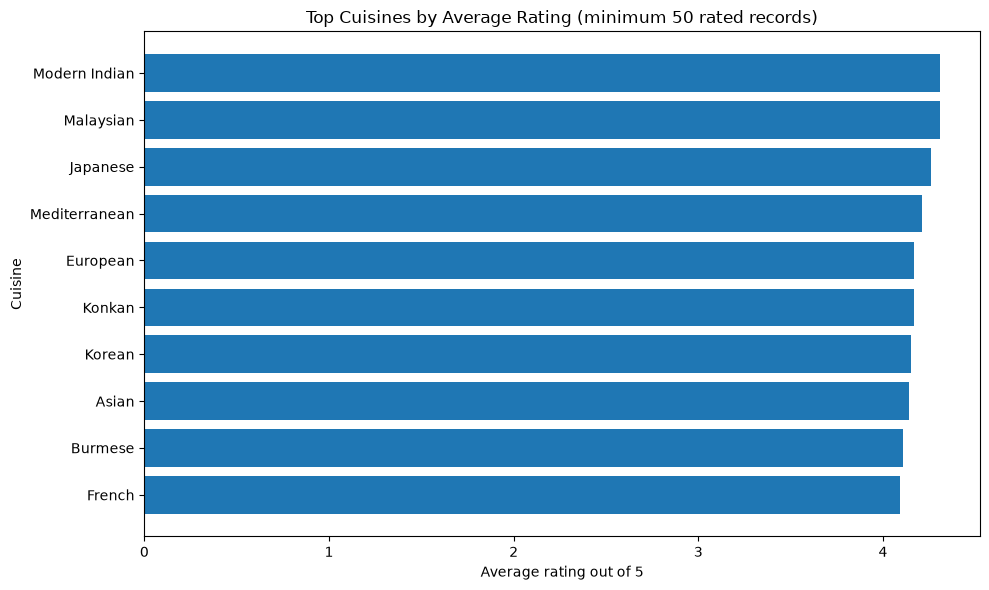

In [6]:
if {"cuisines", "rate_numeric"}.issubset(df_clean.columns):
    cuisine_analysis = (
        df_clean.dropna(subset=["cuisines", "rate_numeric"])
        .assign(cuisine=lambda x: x["cuisines"].astype(str).str.split(","))
        .explode("cuisine")
    )
    cuisine_analysis["cuisine"] = cuisine_analysis["cuisine"].astype(str).str.strip()
    cuisine_analysis = cuisine_analysis[cuisine_analysis["cuisine"].ne("")]
    cuisine_analysis = (
        cuisine_analysis.groupby("cuisine", as_index=False)
        .agg(restaurant_count=("rate_numeric", "size"),
             average_rating=("rate_numeric", "mean"))
    )
    # Require a reasonable sample size to avoid ranking cuisines represented by only a few rows.
    cuisine_top10 = (cuisine_analysis.query("restaurant_count >= 50")
                     .sort_values(["average_rating", "restaurant_count"], ascending=[False, False])
                     .head(10))
    cuisine_top10["average_rating"] = cuisine_top10["average_rating"].round(2)
    display(cuisine_top10)
    if not cuisine_top10.empty:
        plt.figure(figsize=(10, 6))
        plt.barh(cuisine_top10.sort_values("average_rating")["cuisine"],
                 cuisine_top10.sort_values("average_rating")["average_rating"])
        plt.title("Top Cuisines by Average Rating (minimum 50 rated records)")
        plt.xlabel("Average rating out of 5")
        plt.ylabel("Cuisine")
        plt.tight_layout()
        plt.show()
else:
    print("Required columns cuisines/rate_numeric are not available.")

## 6. Business Question 2 — Restaurant count and average cost by location

,location,restaurant_count,average_cost,average_rating
0,BTM,5124,396.48,3.57
22,HSR,2523,475.61,3.67
45,Koramangala 5th Block,2504,663.66,4.01
29,JP Nagar,2235,522.77,3.68
89,Whitefield,2144,598.15,3.62
27,Indiranagar,2083,653.79,3.83
32,Jayanagar,1926,476.41,3.78
56,Marathahalli,1846,513.75,3.54
3,Bannerghatta Road,1630,443.68,3.51
6,Bellandur,1286,527.5,3.53


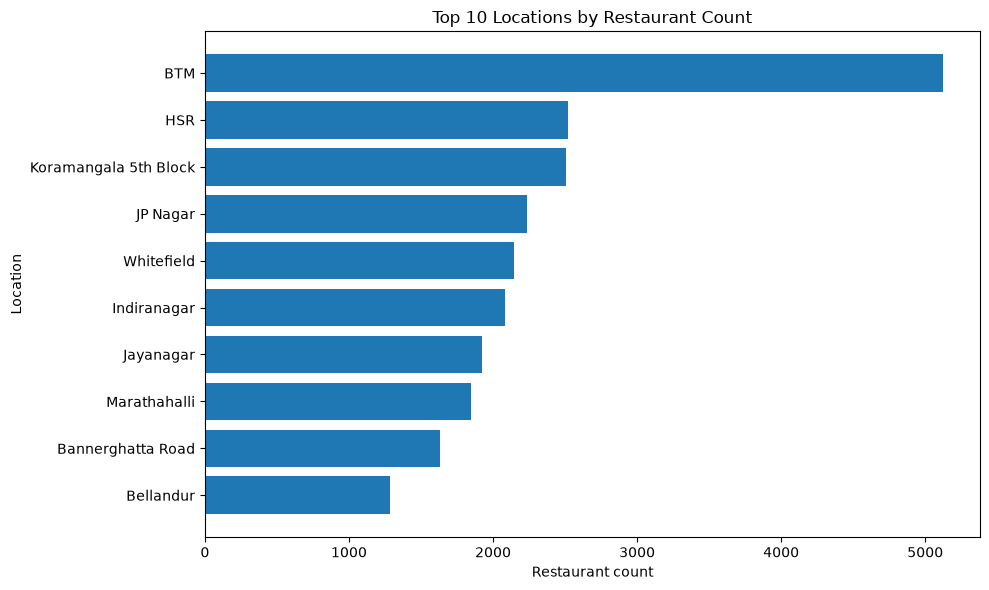

In [7]:
if "location" in df_clean.columns:
    location_analysis = (
        df_clean.dropna(subset=["location"])
        .groupby("location", as_index=False)
        .agg(
            restaurant_count=("name", "count") if "name" in df_clean.columns else ("location", "size"),
            average_cost=("cost_numeric", "mean"),
            average_rating=("rate_numeric", "mean")
        )
        .sort_values("restaurant_count", ascending=False)
    )
    location_analysis[["average_cost", "average_rating"]] = location_analysis[["average_cost", "average_rating"]].round(2)
    display(location_analysis.head(15))
    top_locations_count = location_analysis.head(10)
    plt.figure(figsize=(10, 6))
    plt.barh(top_locations_count.sort_values("restaurant_count")["location"],
             top_locations_count.sort_values("restaurant_count")["restaurant_count"])
    plt.title("Top 10 Locations by Restaurant Count")
    plt.xlabel("Restaurant count")
    plt.ylabel("Location")
    plt.tight_layout()
    plt.show()
else:
    print("Required column 'location' is not available.")

## 7. Business Question 3 — Online order availability vs average rating

,online_order,restaurant_count,rated_restaurants,average_rating
0,No,21273,14459,3.66
1,Yes,30444,27206,3.72


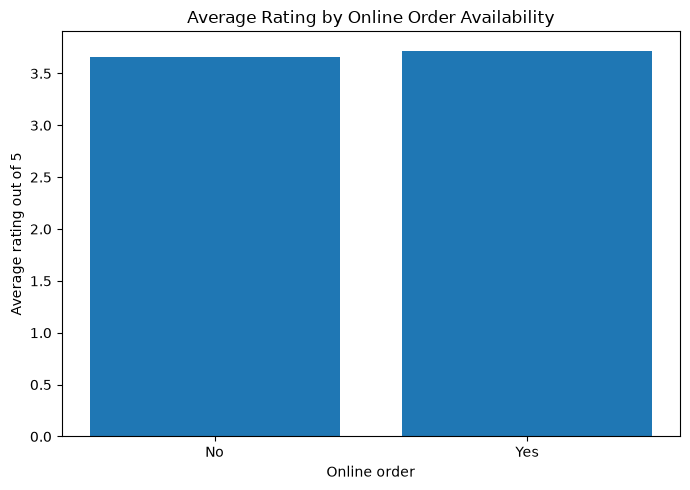

In [8]:
if {"online_order", "rate_numeric"}.issubset(df_clean.columns):
    online_order_analysis = (
        df_clean.groupby("online_order", dropna=False)
        .agg(
            restaurant_count=("rate_numeric", "size"),
            rated_restaurants=("rate_numeric", "count"),
            average_rating=("rate_numeric", "mean")
        ).reset_index()
    )
    online_order_analysis["average_rating"] = online_order_analysis["average_rating"].round(2)
    display(online_order_analysis)
    plot_data = online_order_analysis.dropna(subset=["online_order"])
    plt.figure(figsize=(7, 5))
    plt.bar(plot_data["online_order"].astype(str), plot_data["average_rating"])
    plt.title("Average Rating by Online Order Availability")
    plt.xlabel("Online order")
    plt.ylabel("Average rating out of 5")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns online_order/rate_numeric are not available.")

## 8. Business Question 4 — Restaurant type distribution and average rating

,rest_type,restaurant_count,average_rating
78,Quick Bites,19132,3.55
27,Casual Dining,10330,3.74
19,Cafe,3732,3.85
39,Delivery,2604,3.57
40,Dessert Parlor,2263,3.88
92,"Takeaway, Delivery",2037,3.51
28,"Casual Dining, Bar",1154,4.08
0,Bakery,1141,3.61
14,Beverage Shop,867,3.63
8,Bar,697,3.74


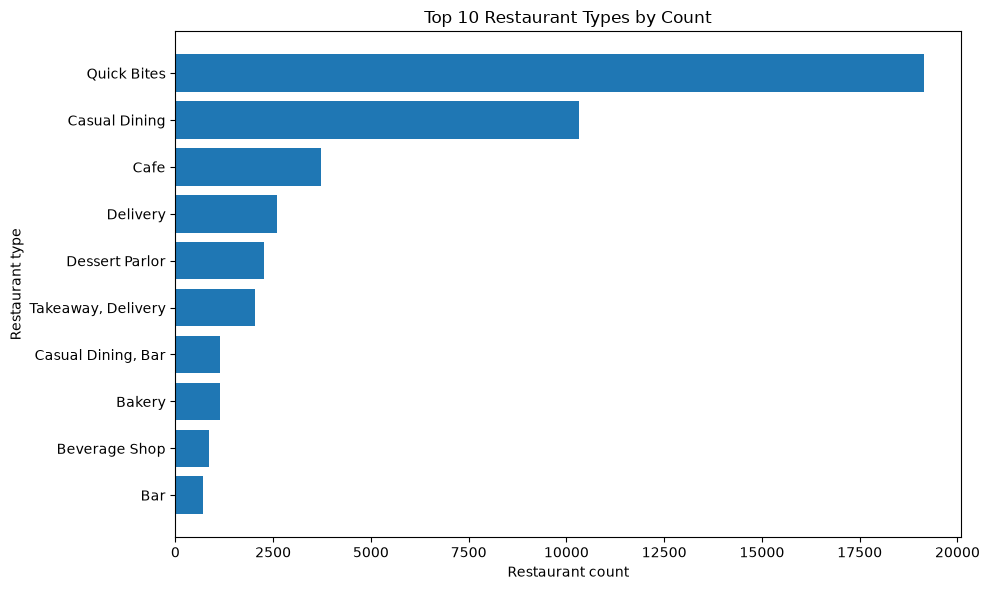

In [9]:
if "rest_type" in df_clean.columns:
    rest_type_analysis = (
        df_clean.dropna(subset=["rest_type"])
        .groupby("rest_type", as_index=False)
        .agg(
            restaurant_count=("name", "count") if "name" in df_clean.columns else ("rest_type", "size"),
            average_rating=("rate_numeric", "mean")
        )
        .sort_values("restaurant_count", ascending=False)
    )
    rest_type_analysis["average_rating"] = rest_type_analysis["average_rating"].round(2)
    display(rest_type_analysis.head(15))
    top_rest_types = rest_type_analysis.head(10).sort_values("restaurant_count")
    plt.figure(figsize=(10, 6))
    plt.barh(top_rest_types["rest_type"], top_rest_types["restaurant_count"])
    plt.title("Top 10 Restaurant Types by Count")
    plt.xlabel("Restaurant count")
    plt.ylabel("Restaurant type")
    plt.tight_layout()
    plt.show()
else:
    print("Required column 'rest_type' is not available.")

## 9. Additional analysis — table booking, votes, and rating distribution

,book_table,restaurant_count,rated_restaurants,average_rating
0,No,45268,35361,3.62
1,Yes,6449,6304,4.14


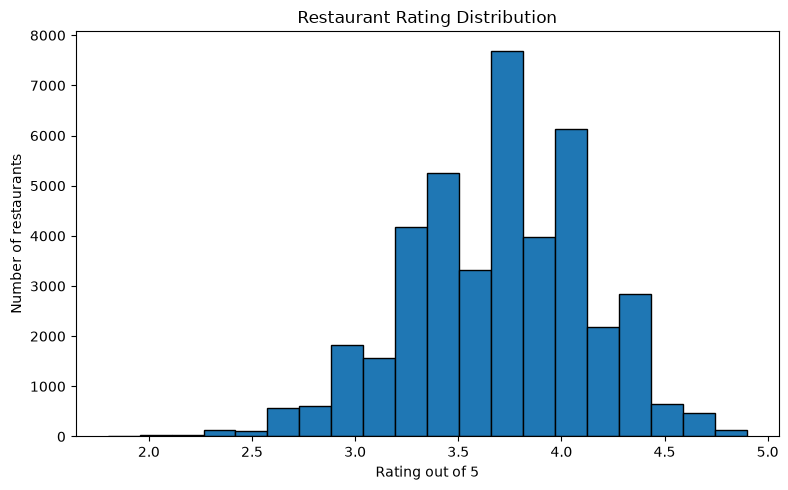

Correlation between votes and ratings: 0.434


,name,location,votes_numeric,rate_numeric
49170,Byg Brewski Brewing Company,Sarjapur Road,16832,4.9
49627,Byg Brewski Brewing Company,Sarjapur Road,16832,4.9
50059,Byg Brewski Brewing Company,Sarjapur Road,16832,4.9
3921,Byg Brewski Brewing Company,Sarjapur Road,16345,4.9
4801,Byg Brewski Brewing Company,Sarjapur Road,16345,4.9
4944,Byg Brewski Brewing Company,Sarjapur Road,16345,4.9
18643,Toit,Indiranagar,14956,4.7
19268,Toit,Indiranagar,14956,4.7
36668,Truffles,Koramangala 5th Block,14726,4.7
33913,Truffles,Koramangala 5th Block,14723,4.7


In [10]:
if {"book_table", "rate_numeric"}.issubset(df_clean.columns):
    table_booking_analysis = (
        df_clean.groupby("book_table", dropna=False)
        .agg(restaurant_count=("rate_numeric", "size"),
             rated_restaurants=("rate_numeric", "count"),
             average_rating=("rate_numeric", "mean"))
        .reset_index()
    )
    table_booking_analysis["average_rating"] = table_booking_analysis["average_rating"].round(2)
    display(table_booking_analysis)

if "rate_numeric" in df_clean.columns:
    plt.figure(figsize=(8, 5))
    df_clean["rate_numeric"].dropna().plot(kind="hist", bins=20, edgecolor="black")
    plt.title("Restaurant Rating Distribution")
    plt.xlabel("Rating out of 5")
    plt.ylabel("Number of restaurants")
    plt.tight_layout()
    plt.show()

if {"votes", "rate_numeric"}.issubset(df_clean.columns):
    df_clean["votes_numeric"] = pd.to_numeric(
        df_clean["votes"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
    print("Correlation between votes and ratings:",
          round(df_clean[["votes_numeric", "rate_numeric"]].corr().iloc[0, 1], 3))
    top_voted = df_clean.nlargest(10, "votes_numeric")
    cols = [c for c in ["name", "location", "votes_numeric", "rate_numeric"] if c in top_voted.columns]
    display(top_voted[cols])

## 10. Business Question 5 — Best-value locations

In [11]:
# Define "value" transparently as a combination of average rating and average cost.
# Locations need at least 30 restaurants with both a rating and a cost.
if "location" in df_clean.columns:
    value_analysis = (
        df_clean.dropna(subset=["location", "rate_numeric", "cost_numeric"])
        .groupby("location", as_index=False)
        .agg(
            restaurant_count=("rate_numeric", "size"),
            average_rating=("rate_numeric", "mean"),
            average_cost=("cost_numeric", "mean")
        )
    )
    value_analysis = value_analysis.query("restaurant_count >= 30 and average_cost > 0")
    # A higher rating and lower cost produce a higher rating-per-100-rupees score.
    value_analysis["value_score"] = value_analysis["average_rating"] / (value_analysis["average_cost"] / 100)
    value_analysis = value_analysis.sort_values("value_score", ascending=False)
    value_analysis[["average_rating", "average_cost", "value_score"]] = value_analysis[["average_rating", "average_cost", "value_score"]].round(2)
    display(value_analysis.head(15))
else:
    print("Required column 'location' is not available.")

,location,restaurant_count,average_rating,average_cost,value_score
13,City Market,75,3.54,323.95,1.09
79,South Bangalore,89,3.5,323.6,1.08
39,Koramangala,30,3.73,351.67,1.06
84,"Varthur Main Road, Whitefield",84,3.58,347.62,1.03
10,CV Raman Nagar,61,3.48,345.08,1.01
73,Sanjay Nagar,48,3.5,348.96,1.0
18,Ejipura,256,3.48,350.98,0.99
4,Basavanagudi,595,3.67,374.12,0.98
14,Commercial Street,270,3.56,376.11,0.95
47,Koramangala 8th Block,220,3.73,396.36,0.94


## 11. Export dashboard-ready CSV for Power BI

In [ ]:
# Keep only the useful columns that exist in the dataset; never fail just because an optional column is absent.
dashboard_columns = [
    "name", "location", "rest_type", "cuisines", "online_order", "book_table",
    "approx_cost(for two people)", "cost_numeric", "votes", "rate_numeric",
    "listed_in(type)", "listed_in(city)"
]
available_dashboard_columns = [c for c in dashboard_columns if c in df_clean.columns]
powerbi_df = df_clean[available_dashboard_columns].copy()
powerbi_df = powerbi_df.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(powerbi_df))
print("Duplicate rows remaining:", powerbi_df.duplicated().sum())

# Export beside the notebook, and also try Downloads for convenience.
dashboard_path = Path.cwd() / "zomato_powerbi_dashboard.cleaned.csv"
powerbi_df.to_csv(dashboard_path, index=False, encoding="utf-8-sig")
print("Power BI CSV exported:", dashboard_path.resolve())
print("Export shape:", powerbi_df.shape)
print("Columns:", powerbi_df.columns.tolist())
print("Valid numeric ratings:", int(powerbi_df["rate_numeric"].notna().sum()))
print("Missing numeric ratings:", int(powerbi_df["rate_numeric"].isna().sum()))

downloads_path = Path.home() / "Downloads" / "zomato_powerbi_dashboard.cleaned.csv"
try:
    downloads_path.parent.mkdir(parents=True, exist_ok=True)
    powerbi_df.to_csv(downloads_path, index=False, encoding="utf-8-sig")
    print("Also saved to:", downloads_path)
except OSError as exc:
    print("Could not save a second copy to Downloads:", exc)

Rows after removing exact duplicates: 51609
Duplicate rows remaining: 0
Power BI CSV exported: C:\Users\acer\Downloads\zomato_powerbi_dashboard.csv
Export shape: (51609, 12)
Columns: ['name', 'location', 'rest_type', 'cuisines', 'online_order', 'book_table', 'approx_cost(for two people)', 'cost_numeric', 'votes', 'rate_numeric', 'listed_in(type)', 'listed_in(city)']
Valid numeric ratings: 41590
Missing numeric ratings: 10019
Also saved to: C:\Users\acer\Downloads\zomato_powerbi_dashboard.csv


## 12. Verify the exported file

In [13]:
check_df = pd.read_csv(dashboard_path, low_memory=False)
print("Export exists:", dashboard_path.exists())
print("Export shape:", check_df.shape)
print("Duplicate rows in export:", int(check_df.duplicated().sum()))
print("Columns in export:", check_df.columns.tolist())
display(check_df.head())

Export exists: True
Export shape: (51717, 12)
Duplicate rows in export: 108
Columns in export: ['name', 'location', 'rest_type', 'cuisines', 'online_order', 'book_table', 'approx_cost(for two people)', 'cost_numeric', 'votes', 'rate_numeric', 'listed_in(type)', 'listed_in(city)']


,name,location,rest_type,cuisines,online_order,book_table,approx_cost(for two people),cost_numeric,votes,rate_numeric,listed_in(type),listed_in(city)
0,Jalsa,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",Yes,Yes,800,800.0,775,4.1,Buffet,Banashankari
1,Spice Elephant,Banashankari,Casual Dining,"Chinese, North Indian, Thai",Yes,No,800,800.0,787,4.1,Buffet,Banashankari
2,San Churro Cafe,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",Yes,No,800,800.0,918,3.8,Buffet,Banashankari
3,Addhuri Udupi Bhojana,Banashankari,Quick Bites,"South Indian, North Indian",No,No,300,300.0,88,3.7,Buffet,Banashankari
4,Grand Village,Basavanagudi,Casual Dining,"North Indian, Rajasthani",No,No,600,600.0,166,3.8,Buffet,Banashankari


## Final notes
- Run every cell from top to bottom using **Kernel → Restart Kernel and Run All**.
- If the first dataset-loading cell reports `FileNotFoundError`, place the original `zomato.csv` beside this notebook or update `candidate_paths`.
- In Power BI, import the newly exported `zomato_powerbi_dashboard.csv`. If the existing dashboard uses an older CSV with a different schema, use **Transform data → Data source settings / Change Source** or re-import the new CSV and reconnect the visuals to the matching columns.